In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:38511")
client

<Client: 'tcp://127.0.0.1:38511' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).chunk({"time":4,"level":1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   # level=slice(1,None)
                                  ).chunk({"time":4,"level":1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>

[2.13 3.85 5.26 6.27] <xarray.DataArray (lp1: 4)> Size: 32B
array([1002.13, 1001.72, 1001.41, 1001.01])
Coordinates:
  * lp1      (lp1) float64 32B 0.5 1.5 2.5 3.5
Fitted Equation: y = 0.0118 * e^(0.2000 * x) + -0.0334


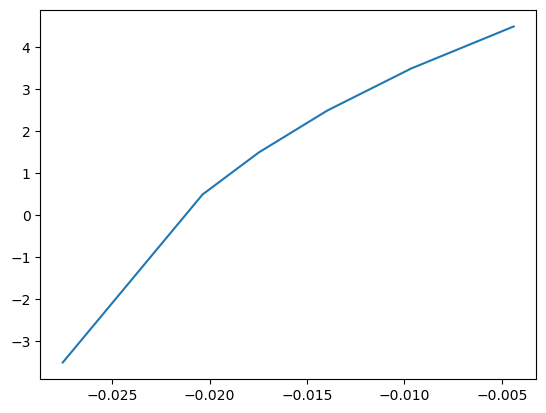

(<xarray.Dataset> Size: 550GB
 Dimensions:  (time: 630, level: 5, y: 2048, x: 4096, lp1: 6, yG: 2047, xG: 4095)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
 Data variables:
     h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     Z        (time, level, y, x) float32

In [5]:
rho0 = 1e3
drho = np.array([2.13, 1.72, 1.41, 1.01,])
rho = xr.DataArray(drho + rho0, 
                   dims="lp1",
                   coords={"lp1":np.array([0.5,1.5,2.5,3.5])}
                  )
print(np.cumsum(drho), rho)

# log_y = np.log(rho)

# # 2. Fit a 1st-degree polynomial (linear fit: y = mx + c)
# # Returns [B, ln(A)]
# coefficients = np.polyfit(rho.lp1.data, log_y, 1)

# # 3. Extract the parameters
# B = coefficients[0]
# A = np.exp(coefficients[1])

# print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x)")

# rp1 = np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5)),]),rho.data)),
#                     np.array([A*np.exp(B*(4.5)),]) 
#                    ))

b = -9.8*(rho - rho0) / rho0

B = 0.2
def exp_func(x, a, c):
    return a * np.exp(B * x) + c

initial_guess = [1, -1e-2]
popt, pcov = curve_fit(exp_func, b.lp1.values, b.values, p0=initial_guess)

# 3. Extract parameters
A, C = popt
print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
plt.plot(A*np.exp(B*np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))+C, 
         np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))
plt.show()

bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
                    np.array([A*np.exp(B*(4.5))+C,]) 
                   )), dims="lp1", 
                   coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                  )

ds2 = ds.copy()

ssh = xr.open_zarr(op.join(ddir,"SW/SSH.zarr")).ssh
dszl = xr.open_zarr(op.join(ddir,"SW/Zl.zarr"))
dsz = xr.open_zarr(op.join(ddir,"SW/Z.zarr"))
ds2["Z"] = dsz.Z.transpose("time","level","y","x").chunk({"level":-1})
Zp1 = xr.concat([dszl.Zl, xr.DataArray(ssh.data[:,:,:,np.newaxis],
                                    dims=dszl.Zl.dims, 
                                    coords={"lp1":np.array([4.5,])})
                ], "lp1")
ds2["Zp1"] = Zp1.transpose("time","lp1","y","x").chunk({"lp1":-1})
ds2["b"] = bp1

llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )
ds2.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds2.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds2, periodic=None, autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })

ds2, grid

In [6]:
dsz = xr.open_zarr(op.join(ddir,"SW/Z.zarr")
                  ).Z.transpose("time","level","y","x"
                               ).to_dataset(name="Z")
dsz["Zl"] = xr.open_zarr(op.join(ddir,"SW/Zl.zarr")
                        ).Zl.transpose("time","lp1","y","x")
dsz.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
dsz.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
dsz.coords["li"] = ("li",ds2.lp1.isel(lp1=slice(1,-1)).data)

gridz = Grid(dsz, periodic=None, autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "left": "lp1", "inner": "li"}
                   })
dsz, gridz

(<xarray.Dataset> Size: 211GB
 Dimensions:  (level: 5, time: 630, x: 4096, y: 2048, lp1: 5, yG: 2047,
               xG: 4095, li: 4)
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * lp1      (lp1) float64 40B -0.5 0.5 1.5 2.5 3.5
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
 Data variables:
     Z        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 4, 128, 256), meta=np.ndarray>
     Zl       (time, lp1, y, x) float32 106GB dask.array<chunksize=(4, 5, 128, 256), meta=np.ndarray>,
 <xgcm.Grid>
 X Axis (not periodic, boundary='fill'):
   * center   x --> inner
 

$$fv = m_\tilde{x};\ fu = -m_\tilde{y}$$

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 140.65 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


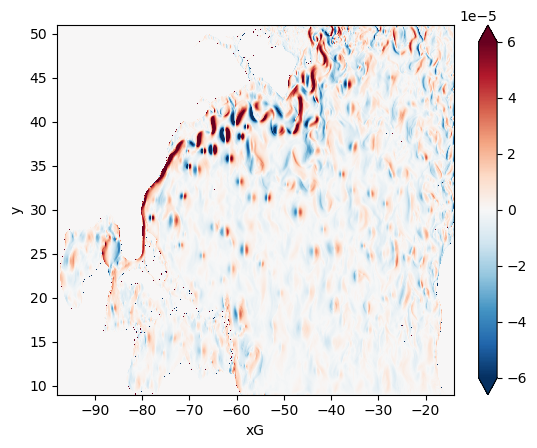

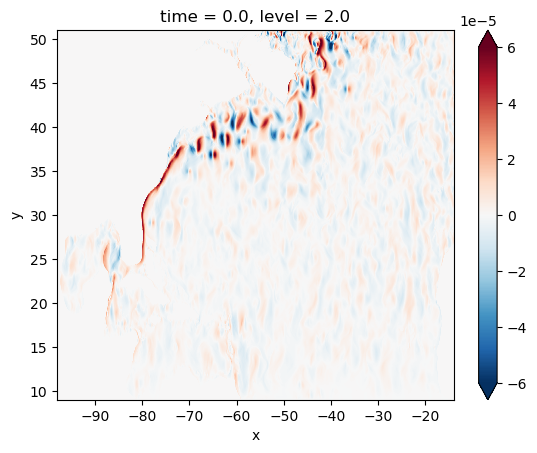

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 140.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


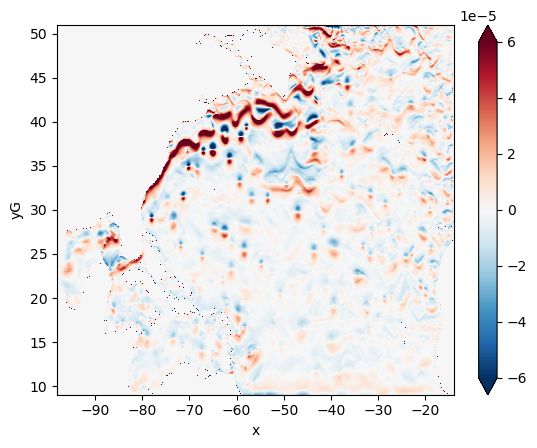

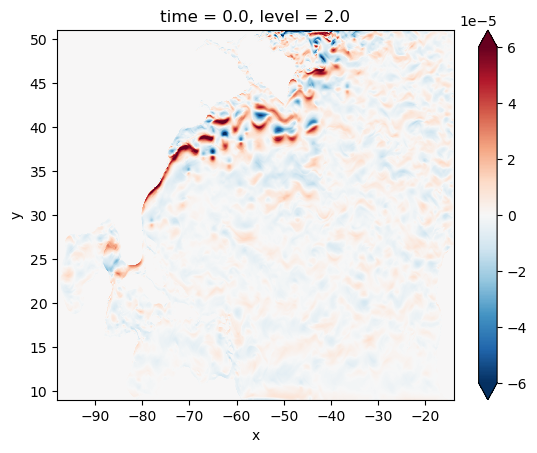

<xarray.Dataset> Size: 169GB
Dimensions:  (time: 630, li: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * li       (li) float64 32B 0.5 1.5 2.5 3.5
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    m        (time, li, y, x) float64 169GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>

In [7]:
rho0 = 1e3
g = 9.8
dr = np.array([.41,.31,.40,1.01])
gp = g*dr/rho0

H = xr.open_zarr(op.join(ddir,"SW/bathy.zarr")).H
eta = -ds2.h.cumsum("level") + H
m = xr.DataArray(np.cumsum(eta.isel(level=slice(None,-1)).data[:,::-1]
                           * gp[np.newaxis,::-1,np.newaxis,np.newaxis], 
                           axis=1)[:,::-1],
                 dims=["time","li","y","x"],
                 coords={"time":ds2.time.data, 
                         "li":ds2.lp1.isel(lp1=slice(1,-1)).data,
                         "y":ds2.y.data, "x":ds2.x.data}
                )

(grid.diff(m.isel(time=0,li=1).chunk({"x":-1}),"X",boundary="extend")
 / xxG).plot(vmax=6e-5, rasterized=True)
plt.show()
cori = gsw.f(ds.y)
(cori * ds["u.y"]).isel(time=0,level=2).plot(vmax=6e-5, rasterized=True)
plt.show()
(-grid.diff(m.isel(time=0,li=1).chunk({"y":-1}),"Y",boundary="extend")
 / yyG).plot(vmax=6e-5, rasterized=True)
plt.show()
cori = gsw.f(ds.y)
(cori * ds["u.x"]).isel(time=0,level=2).plot(vmax=6e-5, rasterized=True)
plt.show()

# phi = g * np.abs(dsz.Z)
# phil = g * np.abs(dsz.Zl)

# m = (phi + grid.interp(ds2.b,"Z",boundary="extend"
#                       )*dsz.Z
#     )
# ml = (phil + ds2.b*dsz.Zl)

# m.chunk({"time":4,"li":1,"y":128,"x":256}
#        ).to_dataset(name="m").to_zarr(op.join(ddir,"SW/Montgomery.zarr"), 
#                                       mode="w")
dsm = xr.open_zarr(op.join(ddir,"SW/Montgomery.zarr"))
dsm

$$\zeta + m_\tilde{b} = 0$$

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 17.74 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


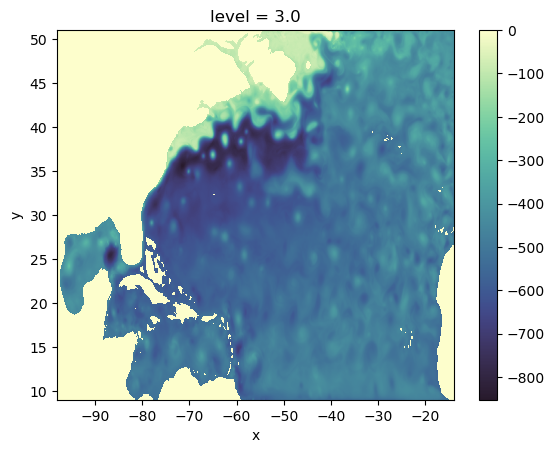

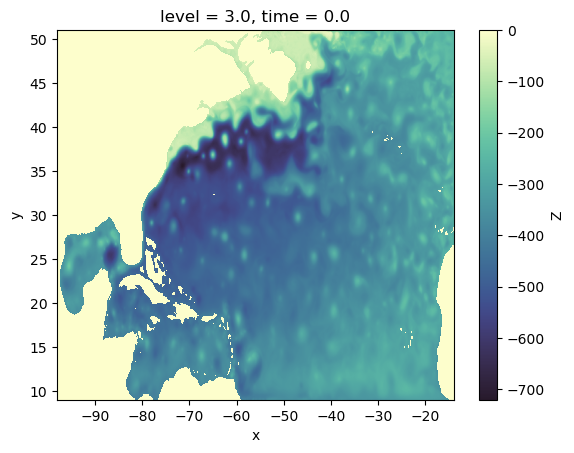

In [27]:
m_b = (gridp.diff(dsm.m,"Z",boundary="extend")
       / grid.diff(ds2.b, "Z", boundary="extend")
      )
m_b.isel(time=0,level=-2).plot(cmap=cmocean.cm.deep_r, rasterized=True)
plt.show()
(-(-dsz.Z)).isel(time=0,level=-2).plot(cmap=cmocean.cm.deep_r, rasterized=True)
plt.show()

In [8]:
dspp = xr.open_zarr(op.join(ddir,"SW/TWA/Upp.zarr"))
dszp = dsz - dsz.mean("time")
mp = dsm.m - dsm.m.mean("time")

(<xarray.DataArray (time: 630, level: 5, y: 2048, x: 4096)> Size: 211GB
 dask.array<truediv, shape=(630, 5, 2048, 4096), dtype=float64, chunksize=(4, 1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<truediv, shape=(4, 2048, 4096), dtype=float64, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01)

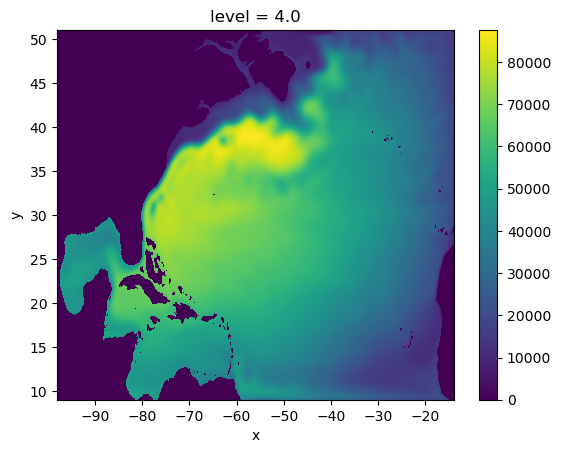

In [14]:
dsb = xr.open_zarr(op.join(ddir,"SW/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )

sig = (ds2.h
       / grid.diff(ds2.b,"Z",boundary="extend")
      )
sigb = (dsb.hbar / grid.diff(ds2.b,"Z",boundary="extend"))
sigb.isel(level=-1).plot(rasterized=True)
sig, sigb

In [ ]:
E00 = (sig * dspp.upp**2).mean("time")
Ediag = .5*(dszp.Z**2).mean("time")
Ecros = (sig * dspp.vpp * dspp.upp).mean("time")
E20 = (-dszp.Zl.isel(lp1=slice(1,None)).data *  # sign convention of zeta
       grid.interp(grid.diff(mp.chunk({"x":-1}),"X",boundary="extend")
                   / xxG,
                   "X",boundary="extend")
      ).mean("time")
E11 = (sig * dspp.vpp**2).mean("time")
E21 = (-dszp.Zl.isel(lp1=slice(1,None)).data *  # sign convention of zeta
       grid.interp(grid.diff(mp.chunk({"y":-1}),"Y",boundary="extend")
                   / yyG,
                   "Y",boundary="extend")
      ).mean("time")
dsave = E00.to_dataset(name="E00")
dsave["Ediag"] = Ediag
dsave["Ecros"] = Ecros
dsave["E20"] = E20
dsave["E11"] = E11
dsave["E21"] = E21
print(dsave)
# dsave.to_zarr(op.join(ddir,"SW/TWA/E-P.zarr"), mode="w")
dsave.close()

dsep = xr.open_zarr(op.join(ddir,"SW/TWA/E-P.zarr"))

dsep.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
dsep.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
dsep.coords["li"] = ("li",dsm.li.data)

gridp = Grid(dsep, periodic=None, autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level", "left": "li"}
                    })

In [11]:
Fu0_x = -gridp.interp(gridp.diff(dsep.E00.chunk({"x":-1}), "X", boundary="extend")
                      / xxG, "X", boundary="extend"
                     )
Fu0 = -((Fu0_x 
         + gridp.interp(gridp.diff(dsep.Ecros.chunk({"y":-1}), "Y", boundary="extend")
                        / yyG, "Y", boundary="extend"
                       )
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fu1 = -(gridp.interp(gridp.diff(dsep.Ediag.chunk({"x":-1}), "X", boundary="extend")
                     / xxG, "X", boundary="extend"
                    ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fu2 = -((gridp.diff(dsep.E20, "Z", boundary="extend"
                   ) / grid.diff(ds2.b, "Z", boundary="extend")
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()

Fv0_x = -gridp.interp(gridp.diff(dsep.Ecros.chunk({"x":-1}), "X", boundary="extend")
                      / xxG, "X", boundary="extend"
                     )
Fv0 = -((Fv0_x 
         + gridp.interp(gridp.diff(dsep.E11.chunk({"y":-1}), "Y", boundary="extend")
                        / yyG, "Y", boundary="extend"
                       )
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fv1 = -(gridp.interp(gridp.diff(dsep.Ediag.chunk({"y":-1}), "Y", boundary="extend")
                     / yyG, "Y", boundary="extend"
                    ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Fv2 = -((gridp.diff(dsep.E21, "Z", boundary="extend"
                   ) / grid.diff(ds2.b, "Z", boundary="extend")
        ) * sigb**-1).isel(level=-2).fillna(0.).compute()

Fu2, Fv2

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 128.44 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 64.26 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.

(<xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
 array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        ...,
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -1.13744705e-08, -8.38121029e-09, -5.17815126e-09],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -5.66409013e-09, -3.62625199e-09, -1.70760015e-09],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -1.09888839e-09, -3.82078191e-10,  4.49531748e-10]],
       shape=(2048, 4096))
 Coordinates:
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -1

In [12]:
Fu = Fu0 + Fu1 + Fu2
Fv = Fv0 + Fv1 + Fv2
Fu, Fv

(<xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
 array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        ...,
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -5.81481159e-08, -2.89693598e-08, -1.24512416e-08],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -5.39879020e-08, -2.58228801e-08, -9.65839787e-09],
        [-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -4.53446431e-08, -2.15227096e-08, -7.55638415e-09]],
       shape=(2048, 4096))
 Coordinates:
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -1

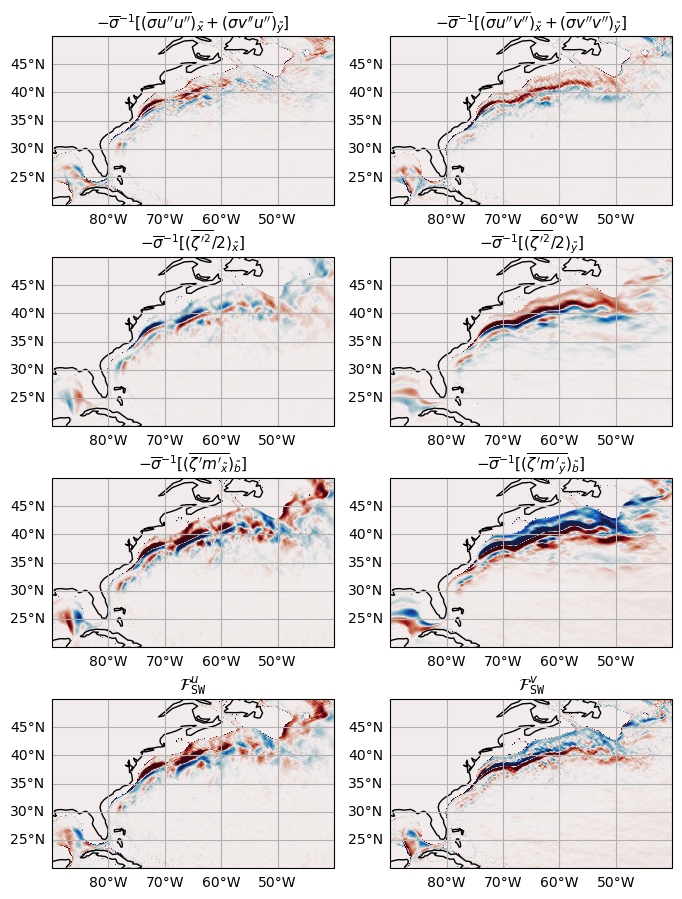

In [28]:
xmax = -40
xmin = -90
ymin = 20
ymax = 50

fig = plt.figure(figsize=(8,11))
ax1 = fig.add_subplot(4, 2, 1, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(4, 2, 3, projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(4, 2, 5, projection=ccrs.PlateCarree())
ax4 = fig.add_subplot(4, 2, 7, projection=ccrs.PlateCarree())
ax5 = fig.add_subplot(4, 2, 2, projection=ccrs.PlateCarree())
ax6 = fig.add_subplot(4, 2, 4, projection=ccrs.PlateCarree())
ax7 = fig.add_subplot(4, 2, 6, projection=ccrs.PlateCarree())
ax8 = fig.add_subplot(4, 2, 8, projection=ccrs.PlateCarree())
ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax3.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax4.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax5.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax6.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax7.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax8.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')
ax3.coastlines(resolution='110m')
ax4.coastlines(resolution='110m')
ax5.coastlines(resolution='110m')
ax6.coastlines(resolution='110m')
ax7.coastlines(resolution='110m')
ax8.coastlines(resolution='110m')
gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False
gl3 = ax3.gridlines(draw_labels=True)
gl3.top_labels = False
gl3.right_labels = False
gl4 = ax4.gridlines(draw_labels=True)
gl4.top_labels = False
gl4.right_labels = False
gl5 = ax5.gridlines(draw_labels=True)
gl5.top_labels = False
gl5.right_labels = False
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False
gl7 = ax7.gridlines(draw_labels=True)
gl7.top_labels = False
gl7.right_labels = False
gl8 = ax8.gridlines(draw_labels=True)
gl8.top_labels = False
gl8.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, Fu0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)
ax2.pcolormesh(dsb.x, dsb.y, Fu1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)
ax3.pcolormesh(dsb.x, dsb.y, Fu2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)
ax4.pcolormesh(dsb.x, dsb.y, Fu, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)

ax5.pcolormesh(dsb.x, dsb.y, Fv0, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)
im = ax6.pcolormesh(dsb.x, dsb.y, Fv1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)
ax7.pcolormesh(dsb.x, dsb.y, Fv2, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)
ax8.pcolormesh(dsb.x, dsb.y, Fv, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)

# ax4.set_xlabel(r"Longitude")
# ax1.set_ylabel(r"Latitude")
# ax2.set_ylabel(r"Latitude")
# ax3.set_ylabel(r"Latitude")
# ax4.set_ylabel(r"Latitude")
ax1.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''u''})_\tilde{x} + (\overline{\sigma v''u''})_\tilde{y}]$", 
              fontsize=11)
ax2.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{x}]$", fontsize=11)
ax3.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{x}})_\tilde{b}]$", 
              fontsize=11)
ax4.set_title(r"$\mathcal{F}^u_{\tt SW}$", fontsize=12)

ax5.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\sigma u''v''})_\tilde{x} + (\overline{\sigma v''v''})_\tilde{y}]$", 
              fontsize=11)
ax6.set_title(r"$-\overline{\sigma}^{-1}[(\overline{{\zeta'}^2}/2)_\tilde{y}]$", fontsize=11)
ax7.set_title(r"$-\overline{\sigma}^{-1}[(\overline{\zeta' m'_\tilde{y}})_\tilde{b}]$", 
              fontsize=11)
ax8.set_title(r"$\mathcal{F}^v_{\tt SW}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_SW.pdf"))

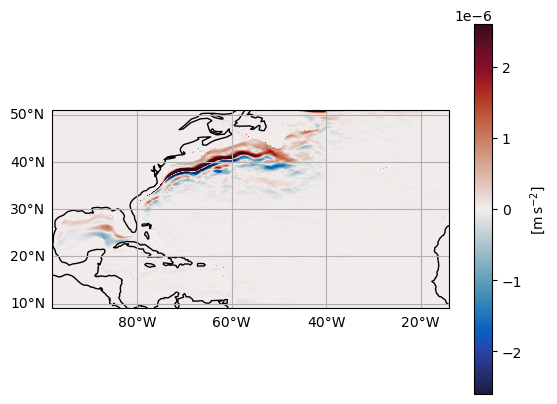

In [34]:
fig = plt.figure()
ax6 = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax6.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax6.coastlines(resolution='110m')
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False

im = ax6.pcolormesh(dsb.x, dsb.y, Fv1, 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2.6e-6, vmax=2.6e-6,
               rasterized=True)

cb = fig.colorbar(im, ax=ax6)
cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_SW_cbar.pdf"))

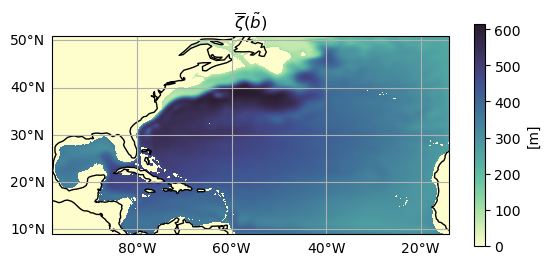

In [29]:
yy = np.arange(10,60,10)
xx = np.arange(-96.,-15,11.5)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsz.x, dsz.y, 
                   np.abs(dsz.Z.isel(level=-2).mean("time")), 
                   cmap=cmocean.cm.deep,
                   rasterized=True)

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{\zeta}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[m]")
plt.savefig(op.join(ddir,"Figs/Z_level-2.pdf"))

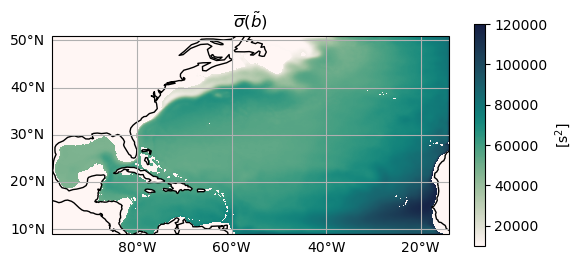

In [32]:
yy = np.arange(10,60,10)
xx = np.arange(-96.,-15,11.5)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsz.x, dsz.y, sigb.isel(level=-2), 
                   cmap=cmocean.cm.tempo,
                   vmin=1e4, vmax=12e4,
                   rasterized=True)

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{\sigma}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[s$^2$]")
plt.savefig(op.join(ddir,"Figs/sig_level-2.pdf"))